## Phase 1: Load and Understand Data

In [8]:
import pandas as pd

df = pd.read_excel('Afficionado Coffee Roasters.xlsx', sheet_name='Transactions')
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [53]:
df.shape

(149116, 18)

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_time  149116 non-null  datetime64[us]
 2   transaction_qty   149116 non-null  int64         
 3   store_id          149116 non-null  int64         
 4   store_location    149116 non-null  str           
 5   product_id        149116 non-null  int64         
 6   unit_price        149116 non-null  float64       
 7   product_category  149116 non-null  str           
 8   product_type      149116 non-null  str           
 9   product_detail    149116 non-null  str           
 10  Hour              149116 non-null  int32         
 11  DayNumber         149116 non-null  int64         
 12  transaction_date  149116 non-null  datetime64[us]
 13  Revenue           149116 non-null  float64       
 14  DayOfWeek      

In [55]:
df.describe()

,transaction_id,transaction_time,transaction_qty,store_id,product_id,unit_price,Hour,DayNumber,transaction_date,Revenue,TimeHours
count,149116.000000,149116,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116,149116.000000,149116.000000
mean,74737.371872,1900-01-01 12:14:15.815795,1.438276,5.342063,47.918607,3.382219,11.735790,104.493428,2025-04-15 11:50:32.173609,4.686367,12.229521
min,1.000000,1900-01-01 06:00:00,1.000000,3.000000,1.000000,0.800000,6.000000,0.000000,2025-01-01 00:00:00,0.800000,6.000000
25%,37335.750000,1900-01-01 09:05:10.500000,1.000000,3.000000,33.000000,2.500000,9.000000,64.000000,2025-03-06 00:00:00,3.000000,9.083333
50%,74727.500000,1900-01-01 11:15:28,1.000000,5.000000,47.000000,3.000000,11.000000,113.000000,2025-04-24 00:00:00,3.750000,11.250000
75%,112094.250000,1900-01-01 15:25:57,2.000000,8.000000,60.000000,3.750000,15.000000,149.000000,2025-05-30 00:00:00,6.000000,15.416667
max,149456.000000,1900-01-01 20:59:32,8.000000,8.000000,87.000000,45.000000,20.000000,180.000000,2025-06-30 00:00:00,360.000000,20.983333
std,43153.600016,NaN,0.542509,2.074241,17.930020,2.658723,3.764662,51.228585,NaN,4.227099,3.766084


In [56]:
df.columns.tolist()

['transaction_id',
 'transaction_time',
 'transaction_qty',
 'store_id',
 'store_location',
 'product_id',
 'unit_price',
 'product_category',
 'product_type',
 'product_detail',
 'Hour',
 'DayNumber',
 'transaction_date',
 'Revenue',
 'DayOfWeek',
 'DayType',
 'TimeBucket',
 'TimeHours']

## Phase 2: Data Cleaning and Validation

In [57]:
df.isnull().sum()

transaction_id      0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
Hour                0
DayNumber           0
transaction_date    0
Revenue             0
DayOfWeek           0
DayType             0
TimeBucket          0
TimeHours           0
dtype: int64

In [58]:
df.duplicated().sum()

np.int64(0)

In [15]:
# duplicate transaction ids
df['transaction_id'].duplicated().sum()

np.int64(0)

In [16]:
# timestamps that fail the HH:MM:SS format
pd.to_datetime(df['transaction_time'].astype(str), format='%H:%M:%S', errors='coerce').isnull().sum()

np.int64(0)

In [17]:
# logical consistency - quantities and prices must be positive
print('Non-positive quantity:', (df['transaction_qty'] <= 0).sum())
print('Non-positive price:', (df['unit_price'] <= 0).sum())

Non-positive quantity: 0
Non-positive price: 0


In [18]:
df['year'].unique()

array([2025])

In [19]:
# year is constant, so it adds nothing to the analysis - dropping it
df.drop(columns=['year'], inplace=True)

## Phase 3: Feature Engineering

In [20]:
# converting time to a proper time format
df['transaction_time'] = pd.to_datetime(df['transaction_time'].astype(str), format='%H:%M:%S')
df['Hour'] = df['transaction_time'].dt.hour
df['Hour'].min(), df['Hour'].max()

(np.int32(6), np.int32(20))

The data has no date column, but rows are ordered by day and then by time. So a new day starts wherever the time goes backwards.

In [21]:
df['DayNumber'] = (df['transaction_time'] < df['transaction_time'].shift()).cumsum()
df['DayNumber'].nunique()

181

In [22]:
# sanity check - every day should start in the morning and end in the evening
df.groupby('DayNumber')['Hour'].agg(['min', 'max']).drop_duplicates()

,min,max
DayNumber,,
0,7,19
6,6,20
9,6,19
12,7,20


181 days is exactly 1 Jan to 30 Jun 2025, so dates are rebuilt assuming the data starts on 1 Jan 2025. Day-of-week labels depend on this assumption.

In [23]:
df['transaction_date'] = pd.Timestamp('2025-01-01') + pd.to_timedelta(df['DayNumber'], unit='D')
df['transaction_date'].agg(['min', 'max'])

min   2025-01-01
max   2025-06-30
Name: transaction_date, dtype: datetime64[us]

In [24]:
# revenue per transaction
df['Revenue'] = df['transaction_qty'] * df['unit_price']

In [25]:
# day of week and weekday/weekend flag
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

df['DayOfWeek'] = df['transaction_date'].dt.day_name()
df['DayType'] = df['DayOfWeek'].apply(lambda d: 'Weekend' if d in ['Saturday', 'Sunday'] else 'Weekday')

In [26]:
# time buckets - morning 6-11, afternoon 12-16, evening 17-21, late hours 22-5
def time_bucket(hour):
    if 6 <= hour <= 11:
        return 'Morning'
    elif 12 <= hour <= 16:
        return 'Afternoon'
    elif 17 <= hour <= 21:
        return 'Evening'
    else:
        return 'Late Hours'

df['TimeBucket'] = df['Hour'].apply(time_bucket)
df['TimeBucket'].value_counts()

TimeBucket
Morning      81751
Afternoon    44427
Evening      22938
Name: count, dtype: int64

In [27]:
df[['transaction_date', 'Hour', 'DayOfWeek', 'DayType', 'TimeBucket', 'Revenue']].head()

,transaction_date,Hour,DayOfWeek,DayType,TimeBucket,Revenue
0,2025-01-01,7,Wednesday,Weekday,Morning,6.0
1,2025-01-01,7,Wednesday,Weekday,Morning,6.2
2,2025-01-01,7,Wednesday,Weekday,Morning,9.0
3,2025-01-01,7,Wednesday,Weekday,Morning,2.0
4,2025-01-01,7,Wednesday,Weekday,Morning,6.2


In [28]:
# store trading hours - first and last transaction of each day, then the typical (median) per store
df['TimeHours'] = df['Hour'] + df['transaction_time'].dt.minute / 60

daily_times = df.groupby(['store_location', 'DayNumber'])['TimeHours'].agg(['min', 'max'])

def to_clock(h):
    minutes = int(round(h * 60))
    return f'{minutes // 60:02d}:{minutes % 60:02d}'

trading_hours = pd.DataFrame({
    'Typical open': daily_times['min'].groupby('store_location').median().apply(to_clock),
    'Typical close': daily_times['max'].groupby('store_location').median().apply(to_clock),
    'Earliest open': daily_times['min'].groupby('store_location').min().apply(to_clock),
    'Latest close': daily_times['max'].groupby('store_location').max().apply(to_clock)
})
trading_hours

,Typical open,Typical close,Earliest open,Latest close
store_location,,,,
Astoria,07:04,19:57,07:00,19:59
Hell's Kitchen,06:37,19:57,06:30,20:59
Lower Manhattan,06:18,18:27,06:00,20:28


The three stores do not trade the same hours: Astoria runs about 7 AM to 8 PM, Hell's Kitchen about 6:30 AM to 8 PM (occasionally later), and Lower Manhattan about 6:15 AM to 6:30 PM, varying a lot by day. So hourly totals at 6 AM and after 6 PM reflect store hours, not weak demand. Only 7:00-17:59 has all three stores trading, so slow hours are judged in that window.

## Phase 4: Sales Trend Analysis

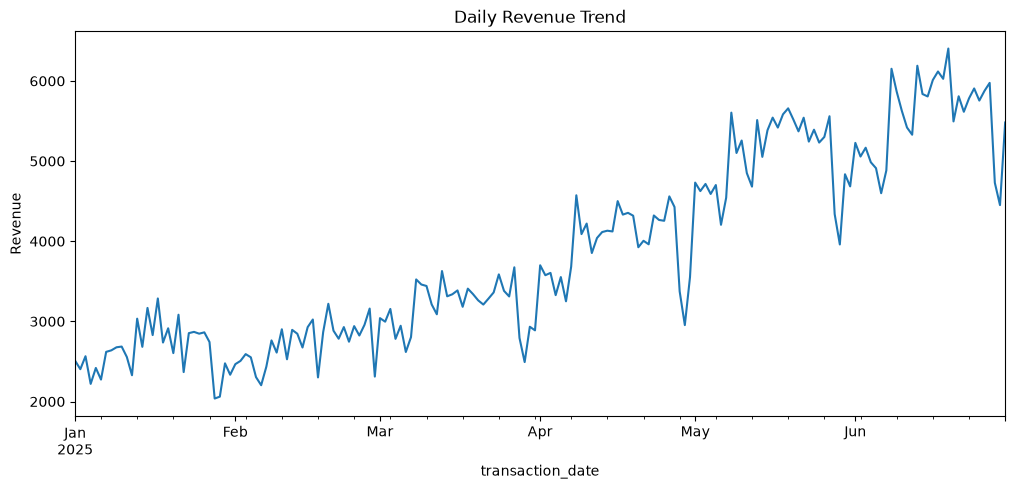

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# daily revenue trend
daily_revenue = df.groupby('transaction_date')['Revenue'].sum()

plt.figure(figsize=(12,5))
daily_revenue.plot()
plt.title('Daily Revenue Trend')
plt.ylabel('Revenue')
plt.show()

In [30]:
# weekly aggregation of revenue and transactions
weekly = df.set_index('transaction_date').resample('W').agg({'Revenue': 'sum', 'transaction_id': 'nunique'})
weekly.columns = ['Revenue', 'Transactions']

# first and last calendar weeks are partial, so they are left out
weekly = weekly.iloc[1:-1]
weekly.head()

,Revenue,Transactions
transaction_date,,
2025-01-12,17777.74,3881
2025-01-19,20648.42,4228
2025-01-26,19485.59,4012
2025-02-02,16623.69,3566
2025-02-09,17458.86,3899


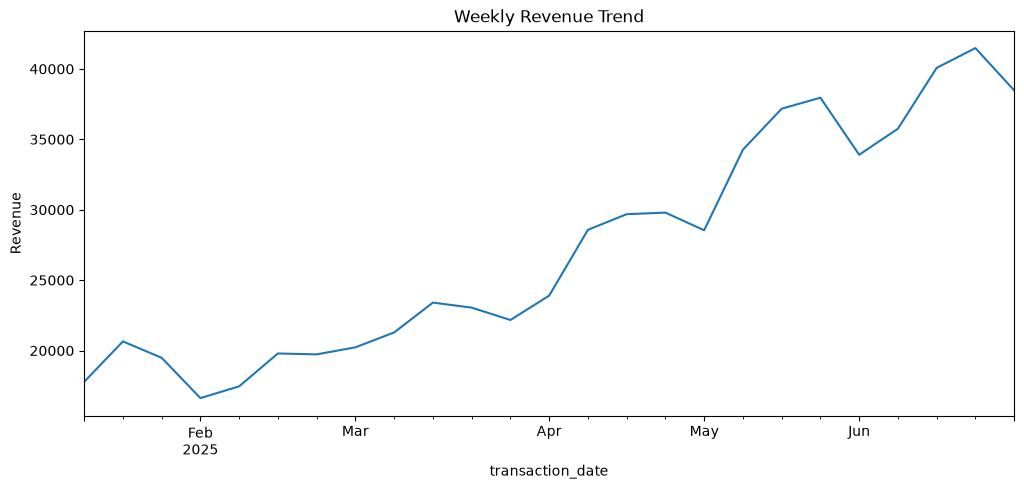

In [31]:
plt.figure(figsize=(12,5))
weekly['Revenue'].plot()
plt.title('Weekly Revenue Trend')
plt.ylabel('Revenue')
plt.show()

In [32]:
# week-over-week change to spot upward/downward patterns
(weekly['Revenue'].pct_change() * 100).round(2).head(10)

transaction_date
2025-01-12      NaN
2025-01-19    16.15
2025-01-26    -5.63
2025-02-02   -14.69
2025-02-09     5.02
2025-02-16    13.37
2025-02-23    -0.33
2025-03-02     2.54
2025-03-09     5.23
2025-03-16     9.95
Freq: W-SUN, Name: Revenue, dtype: float64

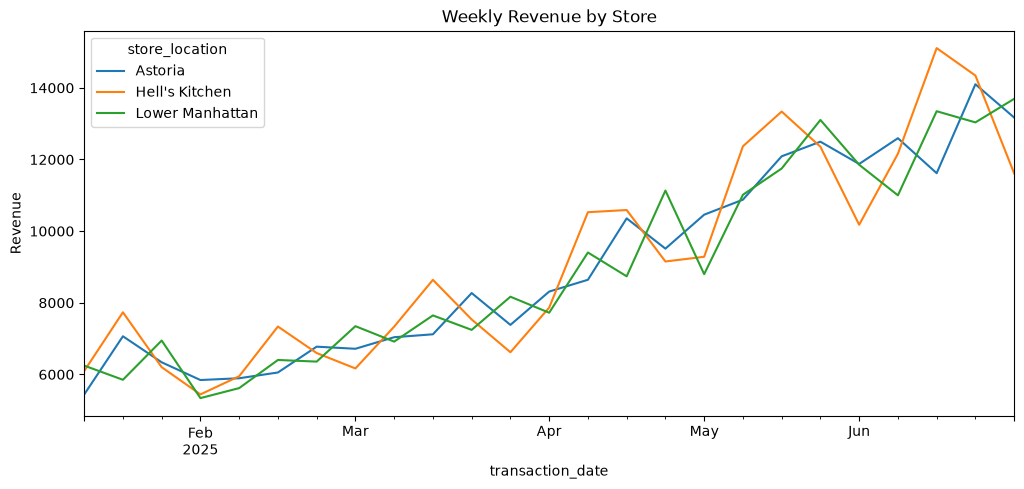

In [33]:
# store-level weekly trend
store_weekly = df.groupby([pd.Grouper(key='transaction_date', freq='W'), 'store_location'])['Revenue'].sum().unstack()
store_weekly = store_weekly.iloc[1:-1]

store_weekly.plot(figsize=(12,5))
plt.title('Weekly Revenue by Store')
plt.ylabel('Revenue')
plt.show()

In [34]:
# is the growth coming from more transactions or from higher prices? compare the first and last 30 days
daily_stats = df.groupby('DayNumber').agg(Revenue=('Revenue', 'sum'), Transactions=('transaction_id', 'nunique'))
daily_stats['AvgTransactionValue'] = daily_stats['Revenue'] / daily_stats['Transactions']

pd.DataFrame({'First 30 days': daily_stats.head(30).mean(), 'Last 30 days': daily_stats.tail(30).mean()}).round(2)

,First 30 days,Last 30 days
Revenue,2644.79,5549.53
Transactions,561.73,1178.40
AvgTransactionValue,4.71,4.71


In [35]:
# growth by store - first 3 vs last 3 full weeks
store_growth = pd.DataFrame({'First 3 weeks': store_weekly.head(3).mean(), 'Last 3 weeks': store_weekly.tail(3).mean()})
store_growth['Growth (x)'] = (store_growth['Last 3 weeks'] / store_growth['First 3 weeks']).round(2)
store_growth.round(2)

,First 3 weeks,Last 3 weeks,Growth (x)
store_location,,,
Astoria,6280.37,12962.33,2.06
Hell's Kitchen,6676.32,13687.65,2.05
Lower Manhattan,6347.23,13358.20,2.10


**Observations from Sales Trend Analysis:**
- Weekly revenue grows steadily across the period, from roughly 18-20k in the first weeks to roughly 38-41k by the end - about double.
- The growth is volume, not price: transactions per day roughly double (about 560 to about 1,180) while the average transaction value stays at 4.71.
- All three stores grow by about the same factor (2.0-2.1x), so the growth is not coming from one location.

## Phase 5: Day-of-Week Performance

In [36]:
# daily totals first, then average per day of week
daily_totals = df.groupby(['transaction_date', 'DayOfWeek', 'DayType']).agg(
    Revenue=('Revenue', 'sum'),
    Transactions=('transaction_id', 'nunique')
).reset_index()

dow_summary = daily_totals.groupby('DayOfWeek')[['Revenue', 'Transactions']].mean().reindex(day_order)
dow_summary

,Revenue,Transactions
DayOfWeek,,
Monday,3898.961538,834.653846
Tuesday,3875.779200,820.400000
Wednesday,3781.935000,811.384615
Thursday,3910.664615,832.423077
Friday,3825.228462,815.461538
Saturday,3858.213077,819.615385
Sunday,3875.683846,832.846154


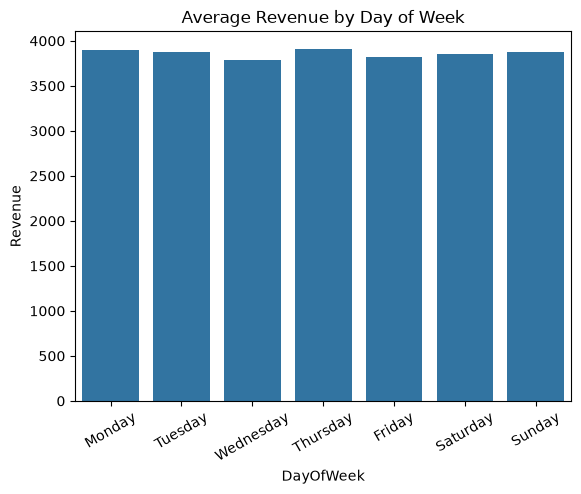

In [37]:
sns.barplot(x=dow_summary.index, y=dow_summary['Revenue'])
plt.title('Average Revenue by Day of Week')
plt.xticks(rotation=30)
plt.show()

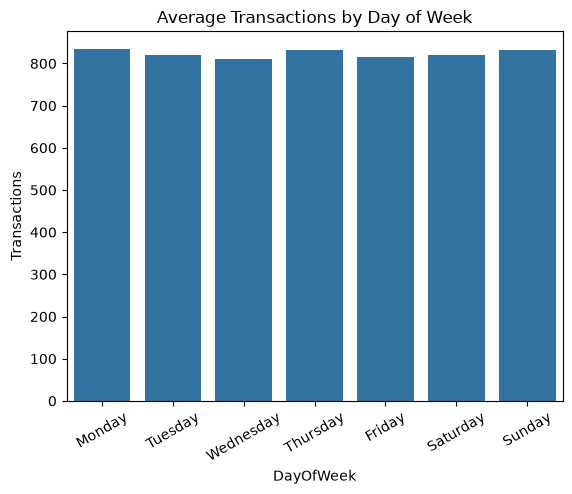

In [38]:
sns.barplot(x=dow_summary.index, y=dow_summary['Transactions'])
plt.title('Average Transactions by Day of Week')
plt.xticks(rotation=30)
plt.show()

In [39]:
# weekday vs weekend
daily_totals.groupby('DayType')[['Revenue', 'Transactions']].mean()

,Revenue,Transactions
DayType,,
Weekday,3858.379922,822.883721
Weekend,3866.948462,826.230769


In [40]:
# sales grow over the period, so raw day averages mix growth with the day effect
# comparing each day with the average of its own week removes the growth (full Monday-Sunday weeks only)
weekly_view = daily_revenue.to_frame('Revenue')
weekly_view['DayOfWeek'] = weekly_view.index.day_name()
weekly_view['Week'] = weekly_view.index.to_period('W-SUN')

full_weeks = weekly_view.groupby('Week').filter(lambda x: len(x) == 7).copy()
full_weeks['DayIndex'] = full_weeks['Revenue'] / full_weeks.groupby('Week')['Revenue'].transform('mean')

full_weeks.groupby('DayOfWeek')['DayIndex'].mean().reindex(day_order).round(3)

DayOfWeek
Monday       0.985
Tuesday      0.992
Wednesday    0.986
Thursday     1.020
Friday       0.992
Saturday     1.013
Sunday       1.013
Name: DayIndex, dtype: float64

In [41]:
# is the difference between days real or just noise?
from scipy import stats

day_groups = [full_weeks[full_weeks['DayOfWeek'] == d]['DayIndex'] for d in day_order]
print('Across 7 days (Kruskal-Wallis):', stats.kruskal(*day_groups))

weekend_flag = full_weeks['DayOfWeek'].isin(['Saturday', 'Sunday'])
print('Weekday vs weekend (Mann-Whitney):', stats.mannwhitneyu(full_weeks[~weekend_flag]['DayIndex'], full_weeks[weekend_flag]['DayIndex']))

Across 7 days (Kruskal-Wallis): KruskalResult(statistic=np.float64(4.9271064935064715), pvalue=np.float64(0.5531957641782914))
Weekday vs weekend (Mann-Whitney): MannwhitneyuResult(statistic=np.float64(2781.0), pvalue=np.float64(0.25656678024849866))


**Observations from Day-of-Week Analysis:**
- Raw day averages differ by only about 3% (Wednesday lowest, Thursday highest), and weekends earn the same as weekdays.
- Because sales grow over the period, each day was also compared with its own week. The day index stays between 0.985 and 1.020, and the difference across days is not statistically significant (Kruskal-Wallis p = 0.55; weekday vs weekend p = 0.26).
- Day of week is not a meaningful driver of demand here, so staffing should follow the hour of day rather than the day of week.

## Phase 6: Time-of-Day Demand Analysis

In [42]:
hourly = df.groupby('Hour').agg(
    Transactions=('transaction_id', 'nunique'),
    Revenue=('Revenue', 'sum')
)
hourly

,Transactions,Revenue
Hour,,
6,4594,21900.27
7,13428,63526.47
8,17654,82699.87
9,17764,85169.53
10,18545,88673.39
11,9766,46319.14
12,8708,40192.79
13,8714,40367.45
14,8933,41304.74


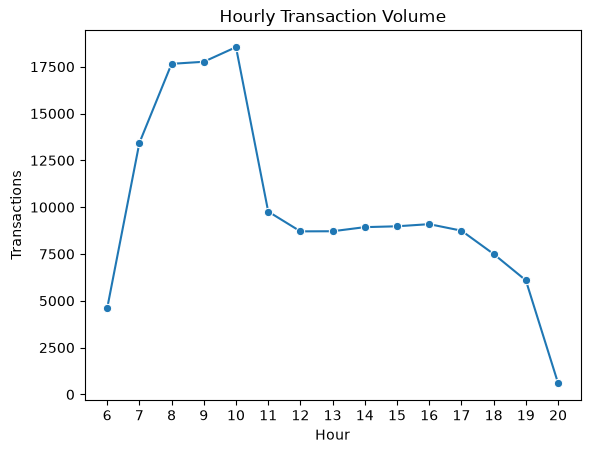

In [43]:
# hourly transaction volume curve
sns.lineplot(x=hourly.index, y=hourly['Transactions'], marker='o')
plt.title('Hourly Transaction Volume')
plt.xticks(hourly.index)
plt.show()

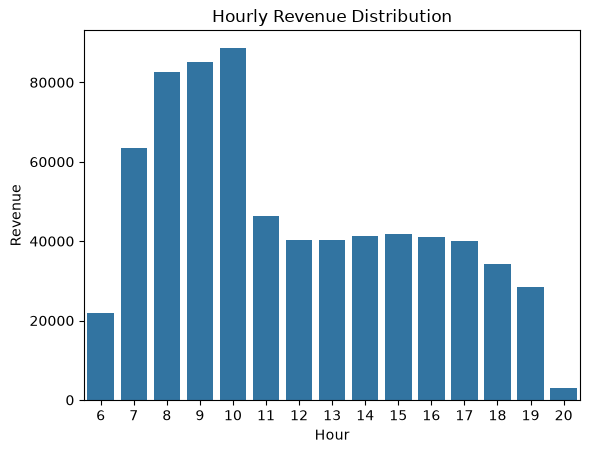

In [44]:
# hourly revenue distribution
sns.barplot(x=hourly.index, y=hourly['Revenue'])
plt.title('Hourly Revenue Distribution')
plt.show()

In [45]:
# revenue share by time bucket
bucket_revenue = df.groupby('TimeBucket')['Revenue'].sum()
(bucket_revenue / bucket_revenue.sum() * 100).round(2)

TimeBucket
Afternoon    29.30
Evening      15.14
Morning      55.56
Name: Revenue, dtype: float64

In [46]:
# rush hours and slow hours
# slow hours are only judged between 7:00 and 17:59, when all three stores are trading (see store trading hours)
full_trading = hourly.loc[7:17]

print('Top 3 hours by transactions:', hourly['Transactions'].nlargest(3).index.tolist())
print('Slowest 3 hours (7-17):', full_trading['Transactions'].nsmallest(3).index.tolist())

Top 3 hours by transactions: [10, 9, 8]
Slowest 3 hours (7-17): [12, 13, 17]


**Observations from Time-of-Day Analysis:**
- Demand peaks between 8 and 10 AM, with 10 AM the busiest hour. Mornings bring in about 56% of revenue.
- After 11 AM demand roughly halves and stays flat (about 8,700-9,100 transactions per hour) until 6 PM. There is no evening peak.
- The low totals at 6 AM and after 6 PM mostly reflect store opening and closing times, not weak demand. The slowest hours between 7 AM and 6 PM are 12, 1 and 5 PM, but the whole afternoon is within about 5% of the same level.
- There are no transactions between 10 PM and 5 AM because the stores are closed, so the Late Hours bucket is empty.

## Phase 7: Cross-Location Temporal Comparison

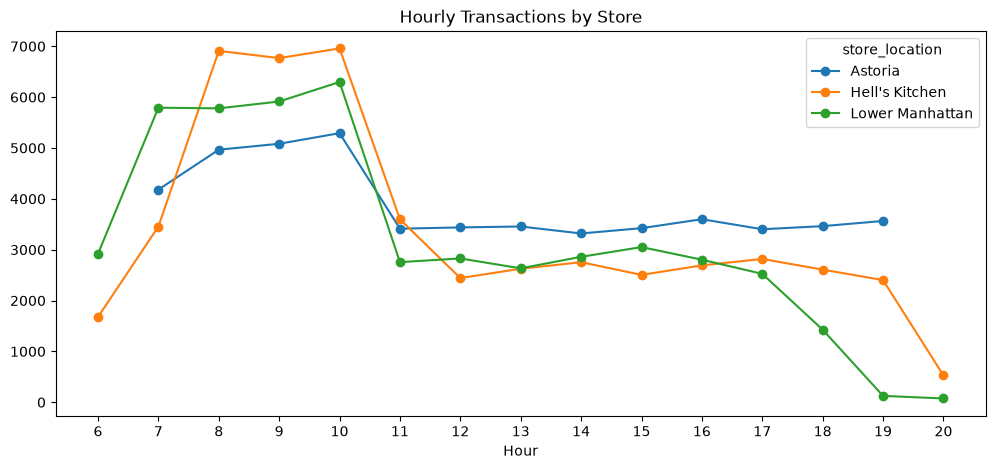

In [47]:
# hourly transactions per store
store_hourly = df.groupby(['Hour', 'store_location'])['transaction_id'].nunique().unstack()

store_hourly.plot(figsize=(12,5), marker='o')
plt.title('Hourly Transactions by Store')
plt.xticks(store_hourly.index)
plt.show()

In [48]:
# average transactions per day by hour and store - makes store opening and closing visible
(store_hourly / df['DayNumber'].nunique()).round(1)

store_location,Astoria,Hell's Kitchen,Lower Manhattan
Hour,,,
6,NaN,9.3,16.1
7,23.1,19.1,32.0
8,27.4,38.2,31.9
9,28.1,37.4,32.7
10,29.2,38.4,34.8
11,18.9,19.9,15.2
12,19.0,13.5,15.6
13,19.1,14.5,14.5
14,18.3,15.2,15.8


In [49]:
# peak hour per store
store_hourly.idxmax()

store_location
Astoria            10
Hell's Kitchen     10
Lower Manhattan    10
dtype: int32

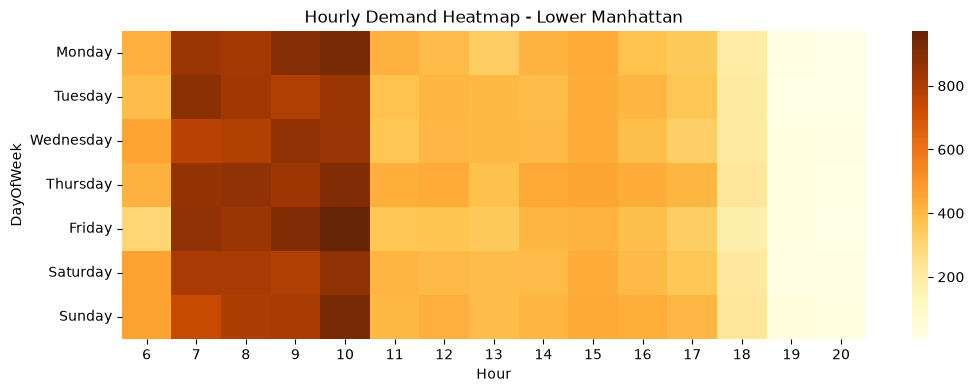

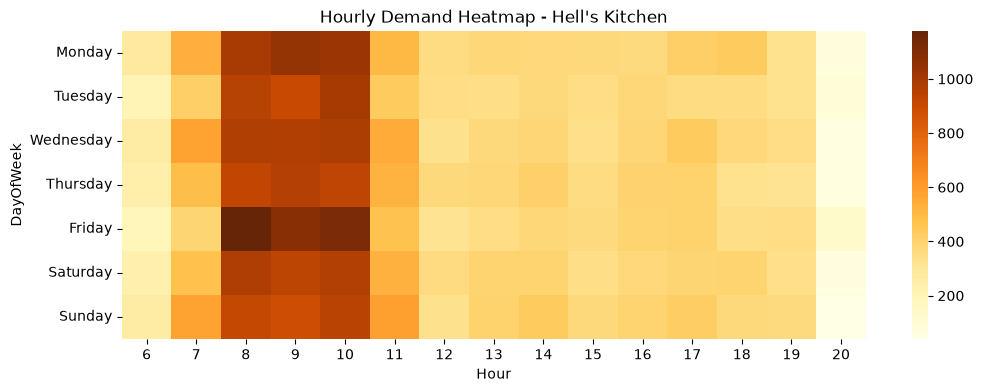

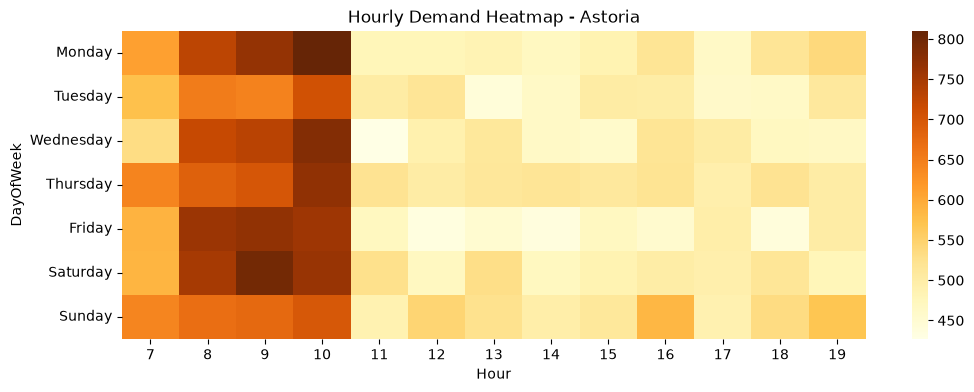

In [50]:
# hourly heatmap per store (day vs hour)
for store in df['store_location'].unique():
    store_df = df[df['store_location'] == store]
    heat = store_df.pivot_table(index='DayOfWeek', columns='Hour', values='transaction_id', aggfunc='nunique').reindex(day_order)

    plt.figure(figsize=(12,4))
    sns.heatmap(heat, cmap='YlOrBr')
    plt.title(f'Hourly Demand Heatmap - {store}')
    plt.show()

In [51]:
# share of store revenue by time bucket
pd.crosstab(df['store_location'], df['TimeBucket'], values=df['Revenue'], aggfunc='sum', normalize='index') * 100

TimeBucket,Afternoon,Evening,Morning
store_location,,,
Astoria,33.829580,20.984081,45.186339
Hell's Kitchen,24.951223,16.090335,58.958442
Lower Manhattan,29.184588,8.264525,62.550887


**Observations from Cross-Location Analysis:**
- All three stores peak at 10 AM, so peak hours are aligned.
- Hell's Kitchen (about 38 transactions per day at 10 AM) and Lower Manhattan (about 35) have sharp morning peaks. Astoria's morning peak is smaller (about 29), but its afternoon demand is the highest and stays flat (about 19 per hour) right up to its 8 PM close.
- Lower Manhattan's weak evenings (about 8% of revenue) mostly come from closing earlier, around 6:30 PM. At 5 PM its demand (about 14 per hour) is close to Hell's Kitchen's (about 16). Astoria has the strongest evenings (about 21%) because it trades steadily until 8 PM.

## Phase 8: Key Metrics Summary

In [59]:
busiest_day = dow_summary['Revenue'].idxmax()
slowest_day = dow_summary['Revenue'].idxmin()
peak_hour = hourly['Transactions'].idxmax()
slowest_hour = full_trading['Transactions'].idxmin()
peak_bucket = bucket_revenue.idxmax()

weekday_avg = daily_totals[daily_totals['DayType'] == 'Weekday']['Revenue'].mean()
weekend_avg = daily_totals[daily_totals['DayType'] == 'Weekend']['Revenue'].mean()

print('Busiest Day:', busiest_day)
print('Slowest Day:', slowest_day)
print('Peak Hour:', peak_hour)
print('Slowest Hour (7-17, all stores trading):', slowest_hour)
print('Peak Time Bucket:', peak_bucket)
print(f'Weekend / Weekday Revenue Ratio: {weekend_avg / weekday_avg:.2f}')

Busiest Day: Thursday
Slowest Day: Wednesday
Peak Hour: 10
Slowest Hour (7-17, all stores trading): 12
Peak Time Bucket: Morning
Weekend / Weekday Revenue Ratio: 1.00
